# Jaccard similarity

Overlap between the *esame* (exam) and *ansia* (anxiety) semantic frames of every sample, human and
GPT-oss. The frame of a word is its set of neighbours in the group's BFMN, and the overlap is the
Jaccard index of the two neighbour sets.

Group differences are tested with participant-level permutation tests: participants of the two
groups are pooled, reassigned at random to groups of the original sizes, and the networks are rebuilt
from their associations. A bootstrap is not used because resampling with replacement duplicates
participants, which shrinks the pooled word sets and biases the Jaccard index downward.


In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import RESSERENO_ROOT
from bfmn_building import text_cleaning, build_association_df
from jaccard_similarity_bfmn import jaccard_similarity, get_sets_of_associations

path_rassereno_analysis = RESSERENO_ROOT / "out" / "analysis"
SPLITS = RESSERENO_ROOT / "out" / "splitted_dfs"

N_PERM = 10000
rng = np.random.default_rng(2026)


## Groups

Export key in `all_bfmns.pkl` -> split file it was built from.


In [2]:
SPLIT_FOLDERS = {
    "high_school": "high_school_2025",
    "physics": "physics_2025",
    "psychology": "psychology_sets_4_5",
    "gpt_oss_high_school": "high_school_gpt_oss",
    "gpt_oss_physics": "physics_gpt_oss",
    "gpt_oss_psychology": "psychology_gpt_oss",
}
GROUPS = {
    f"{name}_{anx}_anx": f"{folder}/{anx}_anx.csv"
    for name, folder in SPLIT_FOLDERS.items()
    for anx in ["high", "low"]
}

with open(path_rassereno_analysis / "all_bfmns.pkl", "rb") as f:
    features = pickle.load(f)


## Participant-level neighbour sets

In the BFMN every cue is linked to each of its associations, so the neighbours of *esame* contributed
by one participant are the words they gave to *esame* plus the cues to which they answered *esame*.
The group's neighbour set is the union over its participants.


In [3]:
def participant_neighbours(split_df, w1="esame", w2="ansia"):
    """List of (neighbours of w1, neighbours of w2), one pair per participant."""
    long_df = build_association_df(text_cleaning(split_df))
    long_df = long_df[long_df["cue_word"] != long_df["word"]]
    pairs = []
    for _, p in long_df.groupby("participant_id"):
        sets = []
        for w in (w1, w2):
            sets.append(
                set(p.loc[p["cue_word"] == w, "word"]) | set(p.loc[p["word"] == w, "cue_word"])
            )
        pairs.append(tuple(sets))
    return pairs


def pooled_jaccard(pairs, idx=None):
    idx = range(len(pairs)) if idx is None else idx
    n1, n2 = set(), set()
    for i in idx:
        n1 |= pairs[i][0]
        n2 |= pairs[i][1]
    return jaccard_similarity(n1, n2) if n1 | n2 else 0.0


neighbours = {g: participant_neighbours(pd.read_csv(SPLITS / f)) for g, f in GROUPS.items()}


## Observed values

`J_frames` is computed from the exported frames (`all_bfmns.pkl`) as a check: it must equal `J`.


In [4]:
rows = []
for g, pairs in neighbours.items():
    anxiety_words, _, exam_words = get_sets_of_associations(features[g])
    rows.append(
        {
            "group": g,
            "N": len(pairs),
            "J": pooled_jaccard(pairs),
            "J_frames": jaccard_similarity(exam_words, anxiety_words),
        }
    )
jaccard = pd.DataFrame(rows).set_index("group")
assert np.allclose(jaccard["J"], jaccard["J_frames"])
jaccard = jaccard.drop(columns="J_frames")
jaccard.round(3).to_csv(path_rassereno_analysis / "jaccard_exam_anxiety.csv")
jaccard.round(3)


,N,J
group,,
high_school_high_anx,30,0.089
high_school_low_anx,27,0.080
physics_high_anx,32,0.111
physics_low_anx,33,0.089
psychology_high_anx,93,0.102
psychology_low_anx,91,0.122
gpt_oss_high_school_high_anx,28,0.050
gpt_oss_high_school_low_anx,30,0.057
gpt_oss_physics_high_anx,33,0.059


## Differences

Humans vs their GPT-oss counterparts (same sample and anxiety group) and high vs low anxiety within each
sample. `p` is the two-sided permutation p-value (share of permuted differences at least as large in
absolute value as the observed one).


In [5]:
def compare(a, b, n_perm=N_PERM):
    pooled = neighbours[a] + neighbours[b]
    n_a = len(neighbours[a])
    observed = jaccard.loc[a, "J"] - jaccard.loc[b, "J"]
    null = np.empty(n_perm)
    for i in range(n_perm):
        order = rng.permutation(len(pooled))
        null[i] = pooled_jaccard(pooled, order[:n_a]) - pooled_jaccard(pooled, order[n_a:])
    return {
        "comparison": f"{a} - {b}",
        "diff": observed,
        "p": (np.sum(np.abs(null) >= abs(observed)) + 1) / (n_perm + 1),
    }


HUMAN_SAMPLES = ["high_school", "physics", "psychology"]
comparisons = [
    compare(f"{s}_{anx}_anx", f"gpt_oss_{s}_{anx}_anx")
    for s in HUMAN_SAMPLES
    for anx in ["high", "low"]
] + [
    compare(f"{prefix}{s}_high_anx", f"{prefix}{s}_low_anx")
    for prefix in ["", "gpt_oss_"]
    for s in HUMAN_SAMPLES
]
comparisons = pd.DataFrame(comparisons).set_index("comparison")
comparisons.round(3).to_csv(path_rassereno_analysis / "jaccard_exam_anxiety_comparisons.csv")
comparisons.round(3)


,diff,p
comparison,,
high_school_high_anx - gpt_oss_high_school_high_anx,0.040,0.201
high_school_low_anx - gpt_oss_high_school_low_anx,0.023,0.344
physics_high_anx - gpt_oss_physics_high_anx,0.052,0.048
physics_low_anx - gpt_oss_physics_low_anx,0.041,0.087
psychology_high_anx - gpt_oss_psychology_high_anx,0.013,0.552
psychology_low_anx - gpt_oss_psychology_low_anx,0.052,0.014
high_school_high_anx - high_school_low_anx,0.010,0.789
physics_high_anx - physics_low_anx,0.022,0.506
psychology_high_anx - psychology_low_anx,-0.020,0.361


## Plot

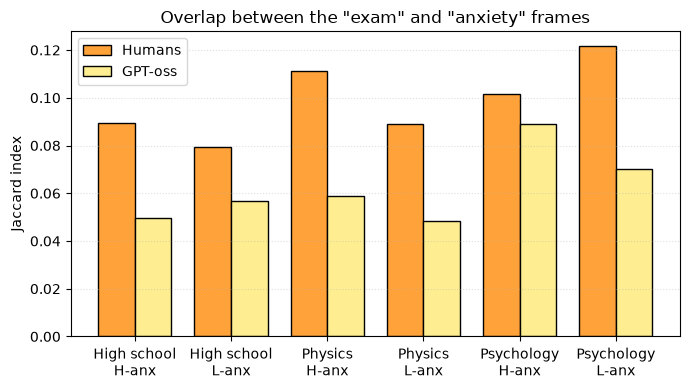

In [6]:
LABELS = {"high_school": "High school", "physics": "Physics", "psychology": "Psychology"}
x_labels = [f"{LABELS[s]}\n{anx}-anx" for s in HUMAN_SAMPLES for anx in ["H", "L"]]
x = np.arange(len(x_labels))
width = 0.38

fig, ax = plt.subplots(figsize=(7, 4))
for j, (prefix, label, colour) in enumerate(
    [("", "Humans", "#FFA239"), ("gpt_oss_", "GPT-oss", "#FEEE91")]
):
    keys = [f"{prefix}{s}_{anx}_anx" for s in HUMAN_SAMPLES for anx in ["high", "low"]]
    sub = jaccard.loc[keys]
    ax.bar(
        x + (j - 0.5) * width,
        sub["J"],
        width,
        label=label,
        color=colour,
        edgecolor="black",
    )
ax.set_xticks(x, x_labels)
ax.set_ylabel("Jaccard index")
ax.set_title('Overlap between the "exam" and "anxiety" frames')
ax.grid(axis="y", linestyle=":", alpha=0.4)
ax.legend()
fig.tight_layout()
(path_rassereno_analysis / "comparison_plots").mkdir(exist_ok=True)
fig.savefig(path_rassereno_analysis / "comparison_plots" / "exam_anxiety_comp.png", dpi=300)
